# Лабораторная работа №3

## Автокодировщики

**Тема**. Автокодировщики. Шумоподавление. Вариационные автокодировщики. Генерация изображений.

**Задание**. Выбрать датасет изображений и исследовать возможность получения компактного латентного представления с помощью автоэнкодера.

In [1]:
import torch_directml

device = torch_directml.device()
print(f"Используемое устройство: {device}")

Используемое устройство: privateuseone:0


In [2]:
import torchvision.transforms as transforms

transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])

In [3]:
from torchvision.datasets import ImageFolder
from PIL import UnidentifiedImageError


class SafeImageFolder(ImageFolder):
    def __getitem__(self, index):
        try:
            return super().__getitem__(index)
        except (UnidentifiedImageError, OSError):
            print(f"[Предупреждение] Пропущен поврежденный файл по индексу {index}")
            new_index = (index + 1) % len(self)
            return self.__getitem__(new_index)

In [4]:
import torchvision.datasets as datasets

# dataset = datasets.ImageFolder(root='./data/PetImages', transform=transform)
dataset = SafeImageFolder(root='./data/PetImages', transform=transform)

## Анализ

баланс

In [5]:
from collections import Counter

print("Классы, найденные ImageFolder:", dataset.classes)
print("Индекс классов:", dataset.class_to_idx)

targets = [target for _, target in dataset.samples]
class_counts = Counter(targets)

for class_idx, count in class_counts.items():
    class_name = dataset.classes[class_idx]
    print(f"Класс '{class_name}': {count} изображений")

print(
    f"Всего изображений в датасете: {sum(class_counts.values())}"
)

Классы, найденные ImageFolder: ['Cat', 'Dog']
Индекс классов: {'Cat': 0, 'Dog': 1}
Класс 'Cat': 12500 изображений
Класс 'Dog': 12499 изображений
Всего изображений в датасете: 24999


Проверка батча

In [6]:
from torch.utils.data import DataLoader

dataloader = DataLoader(dataset, batch_size=64, shuffle=True, num_workers=0)

images, labels = next(iter(dataloader))
print(f"Форма батча с картинками: {images.shape}")
print(f"Форма батча с метками: {labels.shape}")
print(f"Минимальное значение пикселя: {images.min():.4f}")
print(f"Максимальное значение пикселя: {images.max():.4f}")

Форма батча с картинками: torch.Size([64, 3, 64, 64])
Форма батча с метками: torch.Size([64])
Минимальное значение пикселя: 0.0000
Максимальное значение пикселя: 1.0000


Смотрим

In [7]:
import random
import matplotlib.pyplot as plt


def show_sample_images(dataset, n=8):
    fig, axes = plt.subplots(1, n, figsize=(15, 3))
    random_indices = [random.randint(0, len(dataset) - 1) for _ in range(n)]

    for i, idx in enumerate(random_indices):
        img, label = dataset[idx]
        img_np = img.permute(1, 2, 0).numpy()
        axes[i].imshow(img_np)
        axes[i].set_title(dataset.classes[label])
        axes[i].axis("off")
    plt.show()

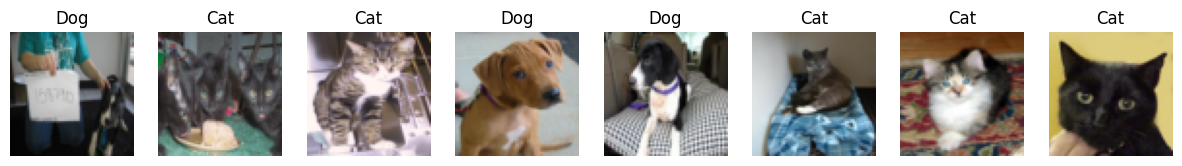

In [8]:
show_sample_images(dataset)

In [9]:
from torch.utils.data import random_split

total_len = len(dataset)
train_size = int(0.6 * total_len)
val_size = int(0.2 * total_len)
test_size = total_len - train_size - val_size

train_dataset, val_dataset, test_dataset = random_split(
    dataset, [train_size, val_size, test_size]
)

## Исследование. Обычный автоэнкодер

In [10]:
BATCH_SIZE = 512

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

Сверточный автоэнкодер

In [11]:
import torch.nn as nn

class ConvAutoencoder(nn.Module):
    def __init__(self, latent_dim=16):
        super(ConvAutoencoder, self).__init__()
        self.latent_dim = latent_dim

        # Энкодер (сжимает 3 x 64 x 64 -> 128 x 8 x 8 -> латентный вектор)
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=2, padding=1),  # -> 32 x 32 x 32
            nn.LeakyReLU(0.2),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),  # -> 64 x 16 x 16
            nn.LeakyReLU(0.2),
            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1), # -> 128 x 8 x 8
            nn.LeakyReLU(0.2),
            nn.Flatten(),
            nn.Linear(128 * 8 * 8, latent_dim)
        )

        # Декодер (зеркально восстанавливает латентный вектор -> 128 x 8 x 8 -> 3 x 64 x 64)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128 * 8 * 8),
            nn.LeakyReLU(0.2),
            nn.Unflatten(1, (128, 8, 8)), # Исправлено с 64 на 128 каналов, чтобы совпадало с энкодером
            nn.ConvTranspose2d(128, 64, kernel_size=3, stride=2, padding=1, output_padding=1), # -> 64 x 16 x 16
            nn.LeakyReLU(0.2),
            nn.ConvTranspose2d(64, 32, kernel_size=3, stride=2, padding=1, output_padding=1),  # -> 32 x 32 x 32
            nn.LeakyReLU(0.2),
            nn.ConvTranspose2d(32, 3, kernel_size=3, stride=2, padding=1, output_padding=1),   # -> 3 x 64 x 64
            nn.Sigmoid()
        )

    def forward(self, x):
        latent = self.encoder(x)
        reconstructed = self.decoder(latent)
        return reconstructed

In [12]:
latent_dims = [2, 8, 16, 32, 64]
results = {}

In [13]:
import torch


EPOCHS = 20

sample_img, _ = test_dataset[0]
device = torch.device('cpu')
sample_tensor = sample_img.unsqueeze(0).to(device)


Запуск модели с латентным пространством: 2


C:\ProjectsPython\ArtificialNeuralNetworksAndDeepLearning\venv_310\lib\site-packages\PIL\TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Эпоха [1/20] | Loss (Train MSE): 0.07329 | Время: 51.05 сек
Эпоха [2/20] | Loss (Train MSE): 0.06731 | Время: 29.79 сек
Эпоха [3/20] | Loss (Train MSE): 0.06590 | Время: 29.72 сек
Эпоха [4/20] | Loss (Train MSE): 0.06233 | Время: 29.78 сек
Эпоха [5/20] | Loss (Train MSE): 0.07494 | Время: 29.46 сек
Эпоха [6/20] | Loss (Train MSE): 0.17197 | Время: 29.71 сек
Эпоха [7/20] | Loss (Train MSE): 0.28333 | Время: 29.86 сек
Эпоха [8/20] | Loss (Train MSE): 0.28415 | Время: 29.72 сек
Эпоха [9/20] | Loss (Train MSE): 0.28379 | Время: 29.91 сек
Эпоха [10/20] | Loss (Train MSE): 0.28471 | Время: 30.04 сек
Эпоха [11/20] | Loss (Train MSE): 0.28470 | Время: 30.69 сек
Эпоха [12/20] | Loss (Train MSE): 0.28463 | Время: 29.70 сек
Эпоха [13/20] | Loss (Train MSE): 0.28462 | Время: 29.54 сек
Эпоха [14/20] | Loss (Train MSE): 0.28467 | Время: 29.65 сек
Эпоха [15/20] | Loss (Train MSE): 0.28467 | Время: 29.59 сек
Эпоха [16/20] | Loss (Train MSE): 0.28467 | Время: 29.86 сек
Эпоха [17/20] | Loss (Train MSE):

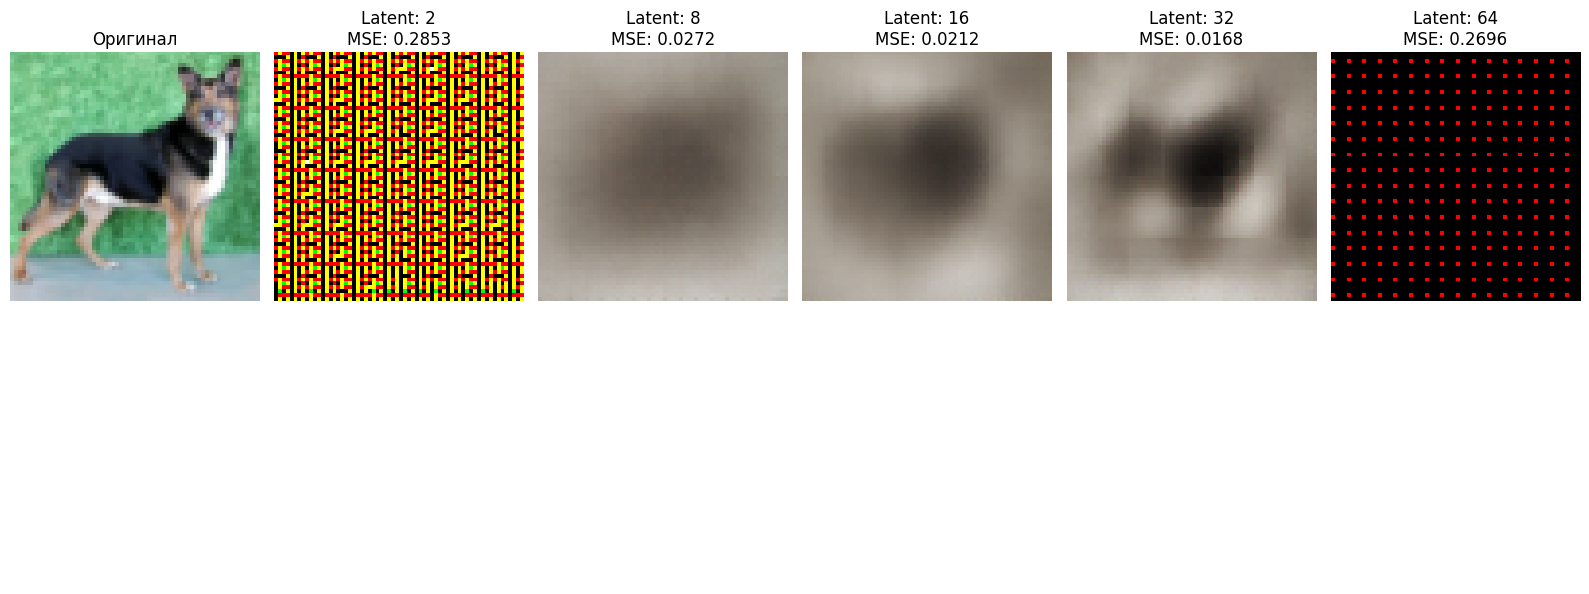

In [14]:
import time
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 6))

plt.subplot(2, len(latent_dims) + 1, 1)
plt.imshow(sample_img.permute(1, 2, 0).numpy())
plt.title("Оригинал")
plt.axis('off')

plt.subplot(2, len(latent_dims) + 1, len(latent_dims) + 2)
plt.axis('off')

results = {}

for idx, dim in enumerate(latent_dims):
    print(f"\nЗапуск модели с латентным пространством: {dim}")

    model = ConvAutoencoder(latent_dim=dim)

    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=0.01) # Увеличили lr для стабильного обучения на CPU
    model.to(device)

    start_time = time.time()
    for epoch in range(EPOCHS):
        epoch_start_time = time.time()

        model.train()
        running_loss = 0.0
        for images, _ in train_loader:
            images = images.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, images)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * images.size(0)

        epoch_time = time.time() - epoch_start_time
        epoch_loss = running_loss / len(train_dataset)


        print(f"Эпоха [{epoch+1}/{EPOCHS}] | Loss (Train MSE): {epoch_loss:.5f} | Время: {epoch_time:.2f} сек")

    train_time = time.time() - start_time
    params_count = sum(p.numel() for p in model.parameters() if p.requires_grad)

    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for images, _ in val_loader:
            images = images.to(device)
            outputs = model(images)
            loss = criterion(outputs, images)
            val_loss += loss.item() * images.size(0)
    final_mse = val_loss / len(val_dataset)


    results[dim] = {
        "MSE": final_mse,
        "Time_sec": train_time,
        "Params": params_count
    }


    with torch.no_grad():
        recon_img = model(sample_tensor).cpu().squeeze(0)

    plt.subplot(2, len(latent_dims) + 1, idx + 2)
    plt.imshow(recon_img.permute(1, 2, 0).numpy())
    plt.title(f"Latent: {dim}\nMSE: {final_mse:.4f}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [15]:
print("\n" + "="*65)
print(f"{'Латент. размер':<15} | {'MSE (Качество)':<15} | {'Общее время (сек)':<18} | {'Параметры':<15}")
print("="*65)
for dim, metrics in results.items():
    print(f"{dim:<15} | {metrics['MSE']:<15.5f} | {metrics['Time_sec']:<18.2f} | {metrics['Params']:<15}")
print("="*65)


Латент. размер  | MSE (Качество)  | Общее время (сек)  | Параметры      
2               | 0.28532         | 616.51             | 227333         
8               | 0.02721         | 616.43             | 325643         
16              | 0.02124         | 610.03             | 456723         
32              | 0.01678         | 610.56             | 718883         
64              | 0.26961         | 604.61             | 1243203        


**Итого:**
Когда латентное пространство равно 2, это очень мало, сеть не смогла ничего закодировать
А при большом латентном пространстве (64) повысился риск переобучения. В моем случае случилось резкое ухудшение на 15 эпохе.
Оптимальное значение 8-32

## Исследование. Denoising autoencoder

Для denoising autoencoder добавить различные виды шума:
* Gaussian noise;
* salt-and-pepper noise;
* masking noise.

Определить, какой шум модель удаляет лучше.

Шумки

In [17]:
def add_gaussian_noise(images, mean=0.0, std=0.2):
    noise = torch.randn_like(images) * std + mean
    noisy_images = torch.clamp(images + noise, 0.0, 1.0)
    return noisy_images

In [18]:
def add_salt_and_pepper_noise(images, salt_prob=0.02, pepper_prob=0.02):
    noisy_images = images.clone()
    salt_mask = torch.rand_like(images) < salt_prob
    noisy_images[salt_mask] = 1.0
    pepper_mask = torch.rand_like(images) < pepper_prob
    noisy_images[pepper_mask] = 0.0
    return noisy_images

In [19]:
def add_masking_noise(images, drop_prob=0.2):
    mask = (torch.rand_like(images) > drop_prob).float()
    noisy_images = images * mask
    return noisy_images

Обучение

In [20]:
OPTIMAL_LATENT_DIM = 32
DAE_EPOCHS = 20

In [22]:
noise_experiments = [
    ("Gaussian Noise", lambda img: add_gaussian_noise(img, std=0.2)),
    ("Salt & Pepper", lambda img: add_salt_and_pepper_noise(img, salt_prob=0.02, pepper_prob=0.02)),
    ("Masking Noise", lambda img: add_masking_noise(img, drop_prob=0.2))
]

In [24]:
dae_results = {}

sample_img, _ = test_dataset[0]
sample_tensor = sample_img.unsqueeze(0).to(device)


Обучение DAE с шумом: Gaussian Noise
Эпоха [1/20] | Loss (MSE): 0.13604 | Время: 32.41 сек
Эпоха [2/20] | Loss (MSE): 0.06293 | Время: 30.97 сек
Эпоха [3/20] | Loss (MSE): 0.05113 | Время: 30.54 сек
Эпоха [4/20] | Loss (MSE): 0.03064 | Время: 30.77 сек
Эпоха [5/20] | Loss (MSE): 0.02489 | Время: 30.83 сек
Эпоха [6/20] | Loss (MSE): 0.02237 | Время: 31.22 сек
Эпоха [7/20] | Loss (MSE): 0.02059 | Время: 30.55 сек
Эпоха [8/20] | Loss (MSE): 0.01961 | Время: 30.52 сек
Эпоха [9/20] | Loss (MSE): 0.02229 | Время: 30.67 сек
Эпоха [10/20] | Loss (MSE): 0.01889 | Время: 30.64 сек
Эпоха [11/20] | Loss (MSE): 0.01802 | Время: 31.00 сек
Эпоха [12/20] | Loss (MSE): 0.01757 | Время: 30.97 сек
Эпоха [13/20] | Loss (MSE): 0.01726 | Время: 30.78 сек
Эпоха [14/20] | Loss (MSE): 0.01705 | Время: 30.98 сек
Эпоха [15/20] | Loss (MSE): 0.01691 | Время: 30.62 сек
Эпоха [16/20] | Loss (MSE): 0.01681 | Время: 30.62 сек
Эпоха [17/20] | Loss (MSE): 0.01687 | Время: 30.39 сек
Эпоха [18/20] | Loss (MSE): 0.01685 

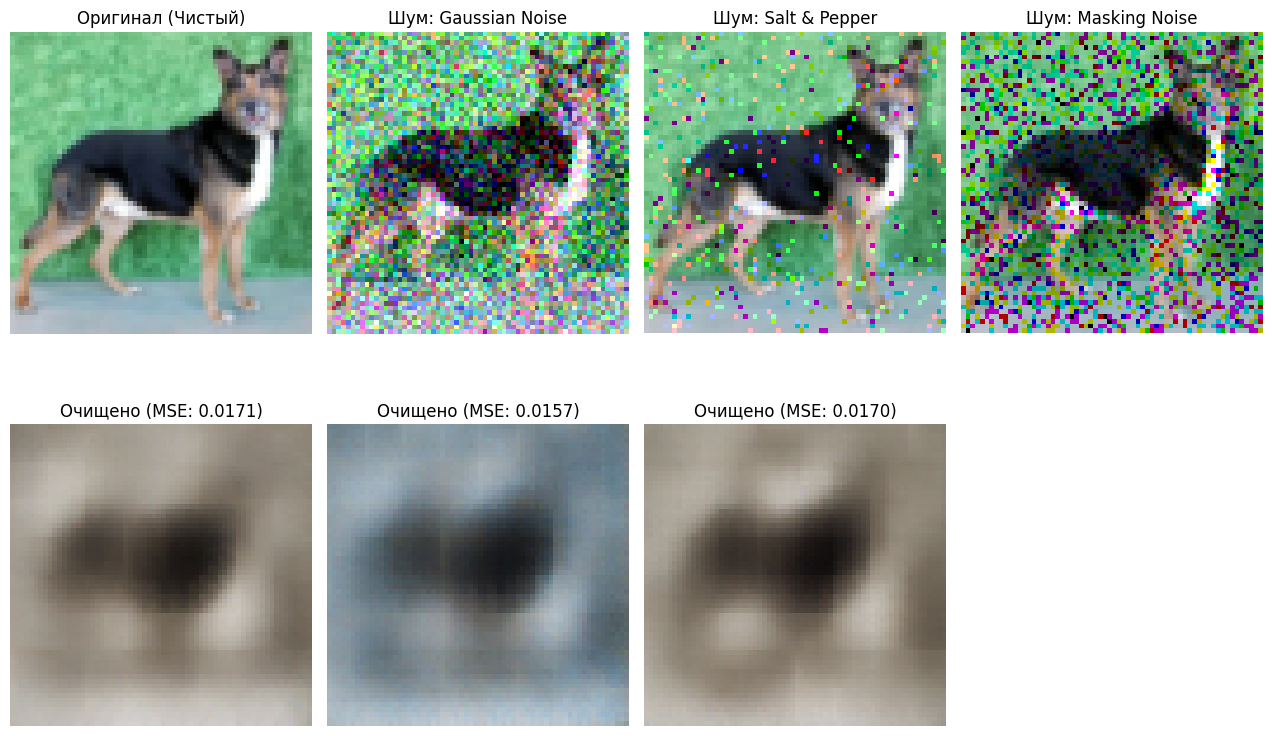

In [27]:
plt.figure(figsize=(16, 8))
plt.subplot(2, len(noise_experiments) + 2, 1)
plt.imshow(sample_img.permute(1, 2, 0).numpy())
plt.title("Оригинал (Чистый)")
plt.axis('off')

for idx, (noise_name, noise_func) in enumerate(noise_experiments):
    print(f"\nОбучение DAE с шумом: {noise_name}")

    model = ConvAutoencoder(latent_dim=OPTIMAL_LATENT_DIM).to(device)
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=0.01)

    start_time = time.time()
    for epoch in range(DAE_EPOCHS):
        epoch_start_time = time.time()

        model.train()
        running_loss = 0.0
        for images, _ in train_loader:
            images = images.to(device)

            noisy_images = noise_func(images)

            optimizer.zero_grad()
            outputs = model(noisy_images)

            loss = criterion(outputs, images)

            loss.backward()
            optimizer.step()
            running_loss += loss.item() * images.size(0)

        epoch_time = time.time() - epoch_start_time
        epoch_loss = running_loss / len(train_dataset)

        print(f"Эпоха [{epoch+1}/{DAE_EPOCHS}] | Loss (MSE): {epoch_loss:.5f} | Время: {epoch_time:.2f} сек")

    train_time = time.time() - start_time

    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for images, _ in val_loader:
            images = images.to(device)
            # На валидации тоже зашумляем вход, чтобы проверить очищение
            noisy_val_images = noise_func(images)
            outputs = model(noisy_val_images)
            loss = criterion(outputs, images) # Сравниваем восстановленное с чистым
            val_loss += loss.item() * images.size(0)

    final_mse = val_loss / len(val_dataset)
    dae_results[noise_name] = {"MSE": final_mse, "Time": train_time}
    print(f"Итоговый MSE на валидации для {noise_name}: {final_mse:.5f}")

    with torch.no_grad():
        noisy_sample = noise_func(sample_tensor)
        cleaned_img = model(noisy_sample).cpu().squeeze(0)

    plt.subplot(2, len(noise_experiments) + 2, idx + 2)
    plt.imshow(noisy_sample.cpu().squeeze(0).permute(1, 2, 0).clamp(0, 1).numpy())
    plt.title(f"Шум: {noise_name}")
    plt.axis('off')

    plt.subplot(2, len(noise_experiments) + 2, idx + len(noise_experiments) + 3)
    plt.imshow(cleaned_img.permute(1, 2, 0).clamp(0, 1).numpy())
    plt.title(f"Очищено (MSE: {final_mse:.4f})")
    plt.axis('off')

plt.tight_layout()
plt.show()

**Итого:** чисто по цифоркам, лучше всех удаляется шум от "перца с солью", но она и первончально выглядела менее шумной. Глобально, визуально все обесшумленные варианты выглядят +- одинаково. Значит выбираю среди тех, где первончально шумов визуально было больше - Гауссовый шум удалился успешнее всего

## Исследование. Вариационный автоэнкодер

Для VAE визуализировать латентное пространство и провести интерполяцию между двумя объектами. Например, взять два изображения A и B, получить их латентные представления и построить последовательность промежуточных изображений.

In [28]:
class VAE(nn.Module):
    def __init__(self, latent_dim=16):
        super(VAE, self).__init__()
        self.latent_dim = latent_dim

        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=4, stride=2, padding=1),  # 64x64 -> 32x32
            nn.LeakyReLU(0.2),
            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1), # 32x32 -> 16x16
            nn.LeakyReLU(0.2),
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1), # 16x16 -> 8x8
            nn.LeakyReLU(0.2),
            nn.Flatten()
        )

        self.fc_mu = nn.Linear(128 * 8 * 8, latent_dim)
        self.fc_var = nn.Linear(128 * 8 * 8, latent_dim)

        self.decoder_input = nn.Linear(latent_dim, 128 * 8 * 8)

        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1), # 8x8 -> 16x16
            nn.LeakyReLU(0.2),
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),  # 16x16 -> 32x32
            nn.LeakyReLU(0.2),
            nn.ConvTranspose2d(32, 3, kernel_size=4, stride=2, padding=1),   # 32x32 -> 64x64
            nn.Sigmoid()
        )

    def encode(self, x):
        h = self.encoder(x)
        mu = self.fc_mu(h)
        logvar = self.fc_var(h)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        h = self.decoder_input(z)
        h = h.view(-1, 128, 8, 8)
        out = self.decoder(h)
        return out

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

У VAE особая функция потерь, которая состоит из двух частей:
* Насколько хорошо картинка восстановилась (MSE)
* KL Divergence (Кулльбак — Лейблер): штраф, который заставляет распределение латентных признаков быть похожим на нормальное распределение

In [29]:
import torch.nn.functional as F

def vae_loss_function(recon_x, x, mu, logvar):
    recon_loss = F.mse_loss(recon_x, x, reduction='sum')
    kld_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())

    return recon_loss + 0.001 * kld_loss

In [31]:
vae_model = VAE(latent_dim=OPTIMAL_LATENT_DIM).to(device)
optimizer = optim.Adam(vae_model.parameters(), lr=0.001)

EPOCHS_VAE = 20

In [32]:
print("Обучения VAE:")
for epoch in range(EPOCHS_VAE):
    epoch_start_time = time.time()

    vae_model.train()
    train_loss = 0.0
    for images, _ in train_loader:
        images = images.to(device)
        optimizer.zero_grad()

        recon_images, mu, logvar = vae_model(images)
        loss = vae_loss_function(recon_images, images, mu, logvar)

        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    epoch_time = time.time() - epoch_start_time
    avg_loss = train_loss / len(train_dataset)

    print(f"Эпоха [{epoch+1}/{EPOCHS_VAE}] | VAE Loss: {avg_loss:.4f} | Время: {epoch_time:.2f} сек")

Обучения VAE:
Эпоха [1/20] | VAE Loss: 658.5955 | Время: 33.55 сек
Эпоха [2/20] | VAE Loss: 390.3361 | Время: 32.54 сек
Эпоха [3/20] | VAE Loss: 300.2816 | Время: 32.88 сек
Эпоха [4/20] | VAE Loss: 260.1910 | Время: 32.32 сек
Эпоха [5/20] | VAE Loss: 236.2376 | Время: 32.51 сек
Эпоха [6/20] | VAE Loss: 219.6464 | Время: 34.04 сек
Эпоха [7/20] | VAE Loss: 215.0679 | Время: 33.46 сек
Эпоха [8/20] | VAE Loss: 205.5888 | Время: 33.63 сек
Эпоха [9/20] | VAE Loss: 202.7729 | Время: 33.33 сек
Эпоха [10/20] | VAE Loss: 201.2765 | Время: 34.16 сек
Эпоха [11/20] | VAE Loss: 200.4570 | Время: 38.16 сек
Эпоха [12/20] | VAE Loss: 199.0647 | Время: 41.94 сек
Эпоха [13/20] | VAE Loss: 194.9284 | Время: 34.74 сек
Эпоха [14/20] | VAE Loss: 189.1816 | Время: 31.98 сек
Эпоха [15/20] | VAE Loss: 188.0541 | Время: 32.14 сек
Эпоха [16/20] | VAE Loss: 186.9598 | Время: 32.26 сек
Эпоха [17/20] | VAE Loss: 185.4121 | Время: 32.48 сек
Эпоха [18/20] | VAE Loss: 186.7014 | Время: 32.76 сек
Эпоха [19/20] | VAE Los

### Латентное пространство на плоскости

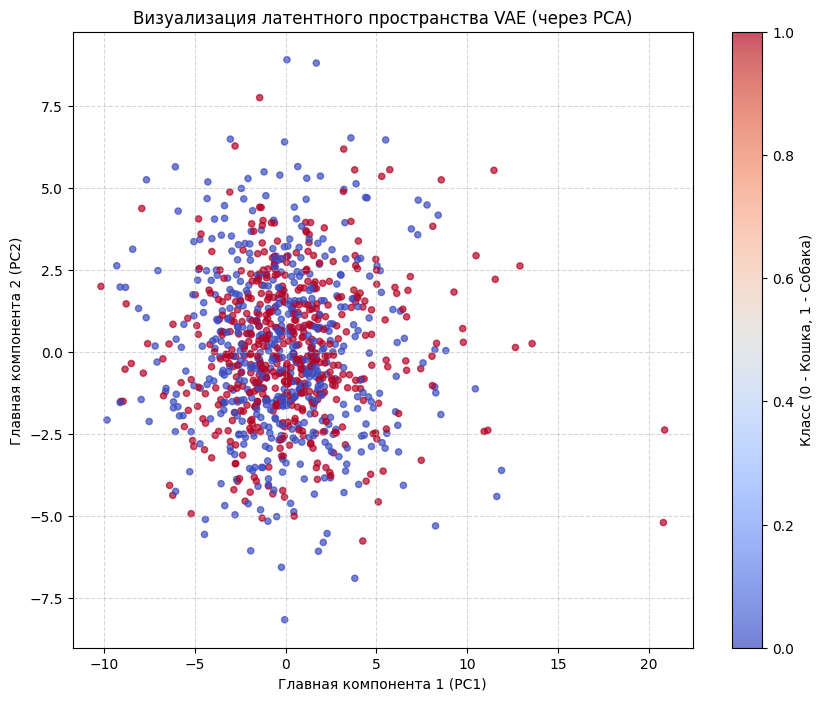

In [34]:
from sklearn.decomposition import PCA

latent_vectors = []
labels_list = []

vae_model.eval()
with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        mu, _ = vae_model.encode(images)
        latent_vectors.append(mu.cpu())
        labels_list.append(labels)

        if len(latent_vectors) * val_loader.batch_size > 1000:
            break

latent_vectors = torch.cat(latent_vectors, dim=0).numpy()
labels_list = torch.cat(labels_list, dim=0).numpy()

pca = PCA(n_components=2)
latent_2d = pca.fit_transform(latent_vectors)

plt.figure(figsize=(10, 8))
scatter = plt.scatter(latent_2d[:, 0], latent_2d[:, 1], c=labels_list, cmap='coolwarm', alpha=0.7, s=20)
plt.colorbar(scatter, label='Класс (0 - Кошка, 1 - Собака)')
plt.title("Визуализация латентного пространства VAE (через PCA)")
plt.xlabel("Главная компонента 1 (PC1)")
plt.ylabel("Главная компонента 2 (PC2)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


хОсновные наблюдения и выводы:

1. Точки распределены в виде компактного облака, плотного в центре и редеющего к краям. Это заслуга регуляризации KL Divergence, которая наводит порядок в латентном пространстве и приближает его к нормальному распределению.
2. На графике нет резких обрывов или изолированных островков
3. Точки перемешаны по всему пространству вместе. Это логично, так как сеть училась просто восстанавливать картинки

### Интерполяция между двумя объектами

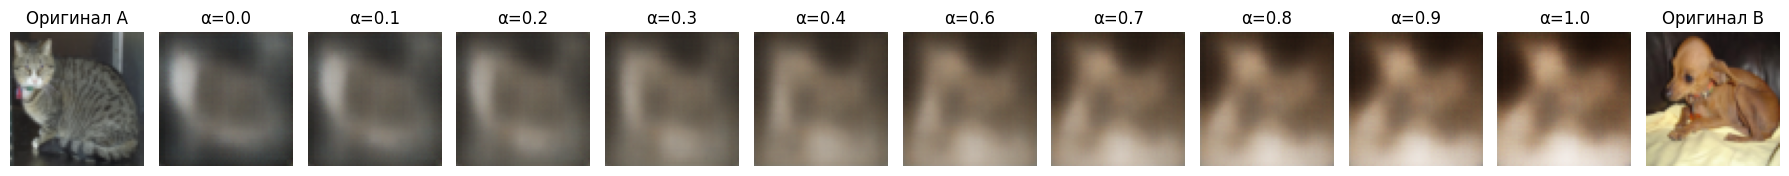

In [36]:
import torch
import matplotlib.pyplot as plt

img_a, _ = val_dataset[0]
img_b, _ = val_dataset[5]

vae_model.eval()
with torch.no_grad():
    tensor_a = img_a.unsqueeze(0).to(device)
    tensor_b = img_b.unsqueeze(0).to(device)

    mu_a, _ = vae_model.encode(tensor_a)
    mu_b, _ = vae_model.encode(tensor_b)

    num_steps = 10
    interpolated_images = []

    for i in range(num_steps):
        alpha = i / (num_steps - 1)
        z_interp = (1.0 - alpha) * mu_a + alpha * mu_b

        decoded_img = vae_model.decode(z_interp)
        interpolated_images.append(decoded_img.cpu().squeeze(0))

total_plots = num_steps + 2

plt.figure(figsize=(18, 3))

plt.subplot(1, total_plots, 1)
plt.imshow(img_a.permute(1, 2, 0).numpy())
plt.title("Оригинал A")
plt.axis('off')

for i, img in enumerate(interpolated_images):
    plt.subplot(1, total_plots, i + 2)
    plt.imshow(img.permute(1, 2, 0).clamp(0, 1).numpy())
    alpha_val = i / (num_steps - 1)
    plt.title(f"α={alpha_val:.1f}")
    plt.axis('off')

plt.subplot(1, total_plots, total_plots)
plt.imshow(img_b.permute(1, 2, 0).numpy())
plt.title("Оригинал B")
plt.axis('off')

plt.tight_layout()
plt.show()

Имеем непрерывный морфинг, латентное пространство VAE плотное, гладкое